In [ ]:
# -*- coding: utf-8 -*-
"""Slope-unit landslide susceptibility mapping for the slope-based system.

Counterpart to RF_XGB_SVM_Mapping.ipynb (the pixel mapping notebook), but the
mapping unit is the slope-unit polygon rather than the pixel. Per-unit conditioning-factor
zonal statistics (mean + stddev of each factor) are PRECOMPUTED inside su_<grid>.gpkg, so no
raster zonal step is needed here: every polygon already carries its feature vector.

For each grid this notebook:
  1. loads the trained slope-unit models (RF / SVM / XGB calibrated + ensemble bundle);
  2. predicts a landslide-susceptibility probability for every slope-unit polygon;
  3. builds the equal-weight mean-probability ensemble;
  4. adds an applicability-domain reliability layer (Mahalanobis domain score + model
     agreement), matching the pixel pipeline;
  5. writes a GeoPackage (per-unit probabilities, AD scores, Jenks class), journal-quality
     PNG maps (per-model, multi-model composite, Jenks 5-class, AD layers including the raw
     Model_disagreement_std), a full set of GeoTIFF rasterisations matching the pixel
     pipeline's maps/ folder (RF/SVM/XGB/Ensemble susceptibility, Domain_score,
     Agreement_score, Applicability_score, Trusted_mask, Model_disagreement_std,
     Mahalanobis_distance), an areal-statistics CSV (by slope-unit area), and a summary JSON.

Assumptions:
  - su_<grid>.gpkg holds ALL slope-unit polygons with the same *_average / *_stddev columns
    used in training (it is the master feature table; the ls_slp_<grid>.csv is the labelled
    training subset only).
  - Models were saved by Slope_Units_Model_Comparision.ipynb into
    slope_unit_model_outputs/<grid>/models/.
"""
!pip install geopandas rasterio jenkspy joblib xgboost scikit-learn shapely -q

import os, gc, json, joblib, warnings
import numpy as np, pandas as pd, geopandas as gpd
import matplotlib as mpl, matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import rasterio
from rasterio import features as rfeatures
from sklearn.covariance import LedoitWolf
from collections import namedtuple
warnings.filterwarnings("ignore")


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 642.0/642.0 kB 8.9 MB/s eta 0:00:00


In [ ]:
from google.colab import drive
# Mount Drive; silently force-remount if the FUSE endpoint dropped.
try:
    drive.mount('/content/drive')
except Exception:
    drive.mount('/content/drive', force_remount=True)


Mounted at /content/drive


In [ ]:
mpl.rcParams.update({
    "font.family":        "DejaVu Sans",
    "font.size":          11,
    "axes.titlesize":     12,
    "axes.titleweight":   "bold",
    "axes.labelsize":     11,
    "axes.linewidth":     1.0,
    "xtick.labelsize":    9,
    "ytick.labelsize":    9,
    "legend.fontsize":    9,
    "figure.dpi":         120,
    "savefig.dpi":        600,
    "savefig.bbox":       "tight",
    "savefig.pad_inches": 0.05,
    "pdf.fonttype":       42,
    "ps.fonttype":        42,
})

MODEL_COLOURS = {"RF": "#2E86AB", "SVM": "#E07A5F", "XGB": "#7E4E90", "Ensemble": "#0E1B2C"}

# Five-class susceptibility palette (Very Low -> Very High)
SUSC_COLOURS = ["#1A9850", "#A6D96A", "#FFFFBF", "#FDAE61", "#D7191C"]
SUSC_LABELS  = ["Very Low", "Low", "Moderate", "High", "Very High"]


In [ ]:
# =========================================================
# 1. PATHS AND SETTINGS
# =========================================================
su_dir = "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/parameters/slopeunits"

# folder where Slope_Units_Model_Comparision.ipynb saved the models
# (each grid has models/Ensemble_<grid>.pkl carrying the {models, features, ...} bundle)
model_base_dir = "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/slope_unit_output"

# susceptibility maps land beside the existing Ensemble map / GeoPackage for each grid
output_base_dir = "/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/slope_unit_maps"
os.makedirs(output_base_dir, exist_ok=True)

grids = ["3x3", "15x15", "25x25"]

RANDOM_STATE  = 42
JENKS_SAMPLE  = 10000     # cap for Jenks break estimation
EXPORT_GEOTIFF = True     # also rasterise the ensemble map to GeoTIFF
RASTER_RES    = 25.0      # GeoTIFF pixel size in metres (CRS is UTM 44N, EPSG:32644)
CRS_LABEL     = "UTM Zone 44N (EPSG:32644)"


In [ ]:
# =========================================================
# 2. HELPERS
# =========================================================
def make_dir(p): os.makedirs(p, exist_ok=True)

def safe_savefig(fig, path, **kw):
    """Save a figure, force-remounting Drive on Errno 107 (ENOTCONN) and retrying once."""
    try:
        fig.savefig(path, **kw)
    except OSError as e:
        if e.errno == 107 or "Transport endpoint" in str(e):
            print(f"⚠️  Drive dropped while saving {os.path.basename(path)} - remounting...")
            from google.colab import drive as _d
            _d.mount('/content/drive', force_remount=True)
            fig.savefig(path, **kw)
        else:
            raise

def load_models_for_grid(grid):
    md = os.path.join(model_base_dir, grid, "models")
    bundle = joblib.load(os.path.join(md, f"Ensemble_{grid}.pkl"))
    feats  = bundle["features"]
    models = bundle["models"]            # {'RF','SVM','XGB'} calibrated estimators
    return bundle, feats, models

def ensemble_predict_proba(models, X):
    cols = [models[m].predict_proba(X)[:, 1] for m in ["RF", "SVM", "XGB"]]
    return np.mean(np.column_stack(cols), axis=1), cols

# ---- applicability domain (same formulation as the pixel mapping pipeline) -------------
def fit_applicability_domain(X_train):
    Xv = X_train.values.astype(np.float64)
    mean_vec = Xv.mean(axis=0)
    precision = LedoitWolf().fit(Xv).precision_
    c = Xv - mean_vec
    train_dist = np.sqrt(np.einsum("ij,jk,ik->i", c, precision, c))
    return {"mean": mean_vec, "precision": precision,
            "threshold": float(np.percentile(train_dist, 95))}

def compute_domain_score(X, ad):
    c = X.values.astype(np.float64) - ad["mean"]
    dist = np.sqrt(np.einsum("ij,jk,ik->i", c, ad["precision"], c))
    score = 1.0 - np.clip(dist / (2.0 * ad["threshold"]), 0, 1)
    return score.astype(np.float32), dist.astype(np.float32)

def compute_agreement_score(prob_cols):
    std = np.std(np.column_stack(prob_cols), axis=1)
    return (1.0 - np.clip(std / 0.5, 0, 1)).astype(np.float32), std.astype(np.float32)

# ---- cartography helper (scale bar + north arrow + CRS tag + UTM-km axes) ---------------
Bounds = namedtuple("Bounds", "left bottom right top")

def bounds_of(gdf):
    minx, miny, maxx, maxy = gdf.total_bounds
    return Bounds(minx, miny, maxx, maxy)

def _add_carto(ax, b, scale_km=5, crs_label=CRS_LABEL):
    bar_frac = (scale_km * 1000.0 / (b.right - b.left)) * 0.95
    bx0 = 0.78; bx1 = min(bx0 + bar_frac, 0.97)
    ax.plot([bx0, bx1], [0.04, 0.04], color="black", lw=4, transform=ax.transAxes,
            solid_capstyle="butt", zorder=10)
    for bx in (bx0, bx1):
        ax.plot([bx, bx], [0.028, 0.052], color="black", lw=1.5, transform=ax.transAxes, zorder=10)
    ax.text(0.5*(bx0+bx1), 0.060, f"{scale_km} km", transform=ax.transAxes, ha="center",
            va="bottom", fontsize=9, bbox=dict(facecolor="white", edgecolor="none", pad=1, alpha=0.85))
    ax.annotate("", xy=(0.95, 0.92), xytext=(0.95, 0.86), xycoords="axes fraction",
                arrowprops=dict(arrowstyle="-|>", color="black", lw=1.6, mutation_scale=18), zorder=10)
    ax.text(0.95, 0.932, "N", transform=ax.transAxes, ha="center", va="bottom",
            fontsize=11, fontweight="bold", zorder=10,
            bbox=dict(facecolor="white", edgecolor="none", pad=1, alpha=0.85))
    ax.text(0.02, 0.97, crs_label, transform=ax.transAxes, ha="left", va="top", fontsize=8,
            zorder=10, bbox=dict(facecolor="white", edgecolor="0.5", pad=2, alpha=0.85))
    xt = np.linspace(b.left, b.right, 5); yt = np.linspace(b.bottom, b.top, 5)
    ax.set_xticks(xt); ax.set_yticks(yt)
    ax.set_xticklabels([f"{int(round(t/1000))}" for t in xt], fontsize=8)
    ax.set_yticklabels([f"{int(round(t/1000))}" for t in yt], fontsize=8)
    ax.set_xlabel("Easting (km, UTM 44N)", fontsize=9)
    ax.set_ylabel("Northing (km, UTM 44N)", fontsize=9)


In [ ]:
# =========================================================
# 3. MAP PLOTTING (slope-unit choropleths)
# =========================================================
def plot_single_map(gdf, column, title, save_path, cmap="RdYlBu_r", vmin=0, vmax=1,
                    cbar_label="Susceptibility probability", scale_km=5):
    b = bounds_of(gdf)
    fig, ax = plt.subplots(figsize=(9, 6.5))
    gdf.plot(column=column, cmap=cmap, vmin=vmin, vmax=vmax, ax=ax, linewidth=0,
             legend=True, legend_kwds={"label": cbar_label, "shrink": 0.6},
             missing_kwds={"color": "lightgrey", "label": "No data"})
    _add_carto(ax, b, scale_km=scale_km)
    ax.set_title(title)
    fig.tight_layout()
    safe_savefig(fig, save_path)
    plt.show(); plt.close(fig)

def plot_multi_model(gdf, grid, save_path, scale_km=5):
    b = bounds_of(gdf)
    fig, axes = plt.subplots(2, 2, figsize=(13, 11))
    last = None
    for ax, name in zip(axes.flat, ["RF", "SVM", "XGB", "Ensemble"]):
        gdf.plot(column=f"{name}_prob", cmap="RdYlBu_r", vmin=0, vmax=1, ax=ax, linewidth=0,
                 missing_kwds={"color": "lightgrey"})
        last = ax.collections[-1]
        ax.set_title(f"{name} susceptibility")
        _add_carto(ax, b, scale_km=scale_km)
    cbar_ax = fig.add_axes([0.92, 0.15, 0.015, 0.7])
    sm = mpl.cm.ScalarMappable(cmap="RdYlBu_r", norm=mpl.colors.Normalize(0, 1))
    fig.colorbar(sm, cax=cbar_ax, label="Landslide susceptibility probability")
    fig.suptitle(f"Slope-unit susceptibility maps - {grid}", y=1.00)
    fig.subplots_adjust(right=0.90, hspace=0.18, wspace=0.12)
    safe_savefig(fig, save_path)
    plt.show(); plt.close(fig)

def jenks_classify(values, n_classes=5):
    import jenkspy
    v = values[np.isfinite(values)]
    s = v if len(v) <= JENKS_SAMPLE else np.random.default_rng(RANDOM_STATE).choice(v, JENKS_SAMPLE, replace=False)
    raw = jenkspy.jenks_breaks(s.tolist(), n_classes=n_classes)
    return [0.0] + sorted(raw)[1:-1] + [1.0]

def plot_classified(gdf, grid, save_path, scale_km=5):
    breaks = jenks_classify(gdf["Ensemble_prob"].values)
    ev = gdf["Ensemble_prob"].values
    cls = np.full(len(gdf), np.nan)
    for k in range(5):
        lo, hi = breaks[k], breaks[k + 1]
        m = np.isfinite(ev) & (ev >= lo) & ((ev <= hi) if k == 4 else (ev < hi))
        cls[m] = k
    gdf["Class"] = cls

    # areal statistics by slope-unit area
    gdf["area_km2"] = gdf.geometry.area / 1e6
    tot = gdf.loc[np.isfinite(cls), "area_km2"].sum()
    rows, lines = [], ["Areal statistics:"]
    for k, lab in enumerate(SUSC_LABELS):
        a = float(gdf.loc[gdf["Class"] == k, "area_km2"].sum())
        n = int((gdf["Class"] == k).sum())
        pct = 100.0 * a / tot if tot else 0.0
        rows.append({"class": lab, "lower": round(breaks[k], 4), "upper": round(breaks[k + 1], 4),
                     "units": n, "area_km2": round(a, 2), "percent": round(pct, 2)})
        lines.append(f"{lab:<10}{pct:>6.1f}%  ({a:>7.2f} km2)")

    cmap = mpl.colors.ListedColormap(SUSC_COLOURS)
    b = bounds_of(gdf)
    fig, ax = plt.subplots(figsize=(11, 7.5))
    gdf.plot(column="Class", cmap=cmap, vmin=0, vmax=4, ax=ax, linewidth=0,
             missing_kwds={"color": "lightgrey"})
    handles = [mpatches.Patch(facecolor=SUSC_COLOURS[k], edgecolor="0.4", label=SUSC_LABELS[k])
               for k in range(5)]
    ax.legend(handles=handles, title="Susceptibility class", loc="upper right", framealpha=0.9)
    ax.text(0.02, 0.18, "\n".join(lines), transform=ax.transAxes, fontsize=9,
            family="DejaVu Sans Mono", va="bottom",
            bbox=dict(boxstyle="round,pad=0.4", facecolor="white", edgecolor="0.5", alpha=0.9))
    _add_carto(ax, b, scale_km=scale_km)
    ax.set_title(f"Slope-unit susceptibility (Jenks 5-class) - {grid}")
    fig.tight_layout()
    safe_savefig(fig, save_path)
    plt.show(); plt.close(fig)
    return pd.DataFrame(rows)

def rasterize_column(gdf, column, save_path, res=RASTER_RES, fill=-9999.0):
    """Burn one per-unit attribute column into a single-band float32 GeoTIFF.

    Polygons are rasterised at `res` metres on the shared slope-unit extent so every
    layer (susceptibility, AD scores, masks) lands on an identical grid - matching the
    pixel pipeline's maps/ folder. Units with a NaN value are left as nodata.
    """
    minx, miny, maxx, maxy = gdf.total_bounds
    width  = int(np.ceil((maxx - minx) / res))
    height = int(np.ceil((maxy - miny) / res))
    transform = rasterio.transform.from_origin(minx, maxy, res, res)
    valid = gdf[gdf[column].notna()]
    shapes = ((geom, float(v)) for geom, v in zip(valid.geometry, valid[column]))
    arr = rfeatures.rasterize(shapes, out_shape=(height, width), transform=transform,
                              fill=fill, dtype="float32")
    profile = dict(driver="GTiff", height=height, width=width, count=1, dtype="float32",
                   crs=gdf.crs, transform=transform, nodata=fill, compress="lzw")
    with rasterio.open(save_path, "w", **profile) as dst:
        dst.write(arr, 1)

def rasterize_ensemble(gdf, save_path, res=RASTER_RES):
    rasterize_column(gdf, "Ensemble_prob", save_path, res=res)



========================= GRID: 3x3 =========================
  features used by models (18): ['aspect_average', 'aspect_stddev', 'curvature_average', 'curvature_stddev', 'dis_to_fault_average', 'dis_to_fault_stddev', 'dis_to_river_average', 'dis_to_river_stddev', 'dis_to_road_average', 'dis_to_road_stddev', 'dis_to_thrust_average', 'dis_to_thrust_stddev', 'ndvi_average', 'ndvi_stddev', 'slope_average', 'slope_stddev', 'twi_average', 'twi_stddev']
  slope-unit polygons: 9952 | CRS: EPSG:32644
  valid units (no NaN in features): 9875 / 9952
  wrote GeoPackage: /content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/slope_unit_maps/3x3/maps/Slope_susceptibility_3x3.gpkg


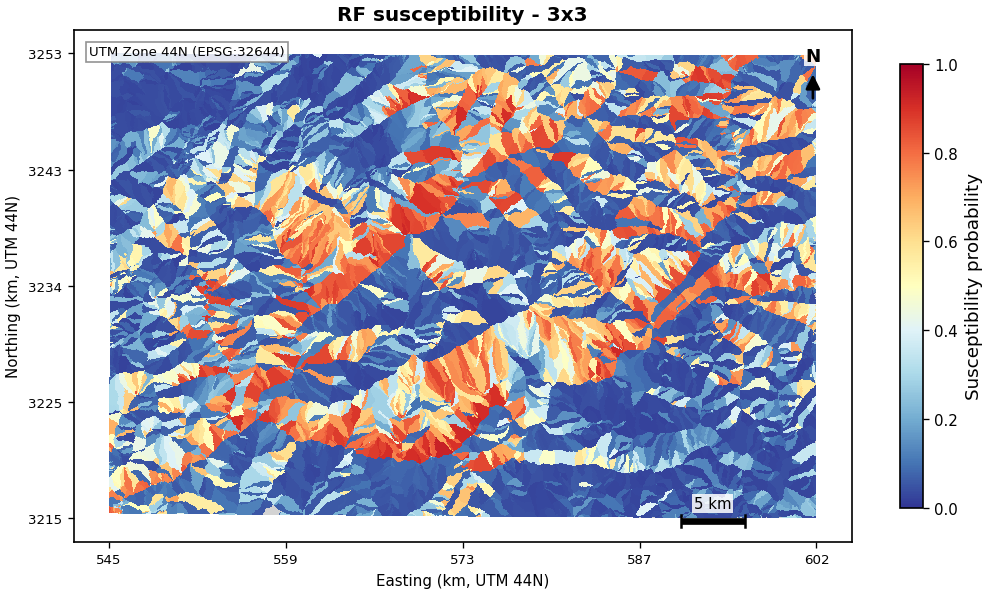

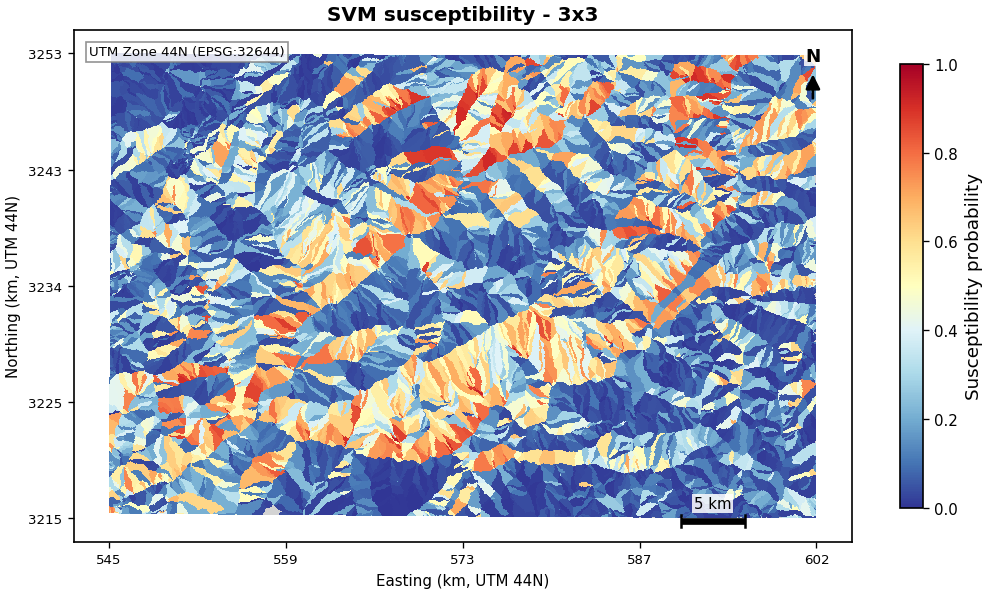

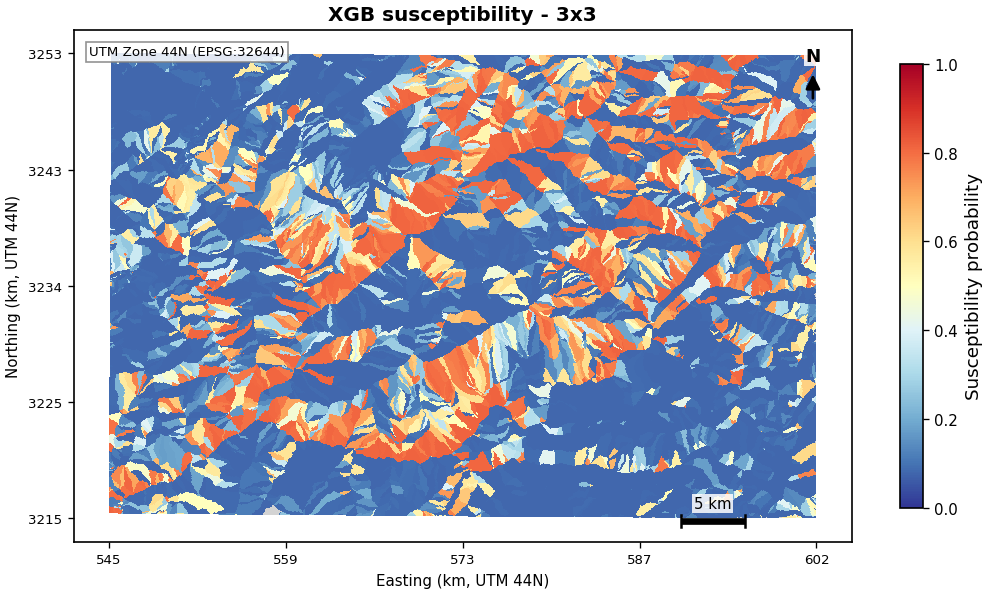

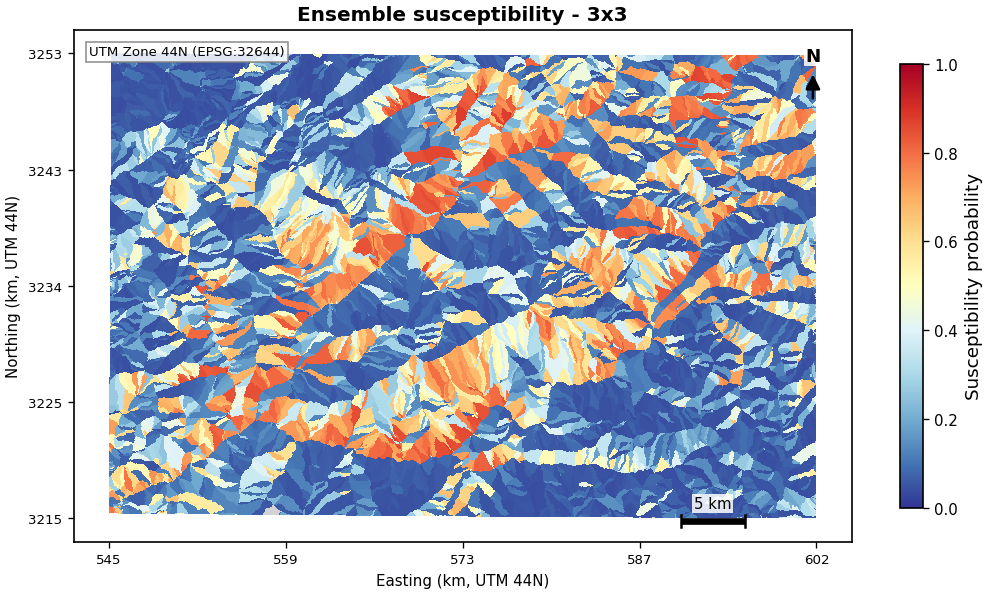

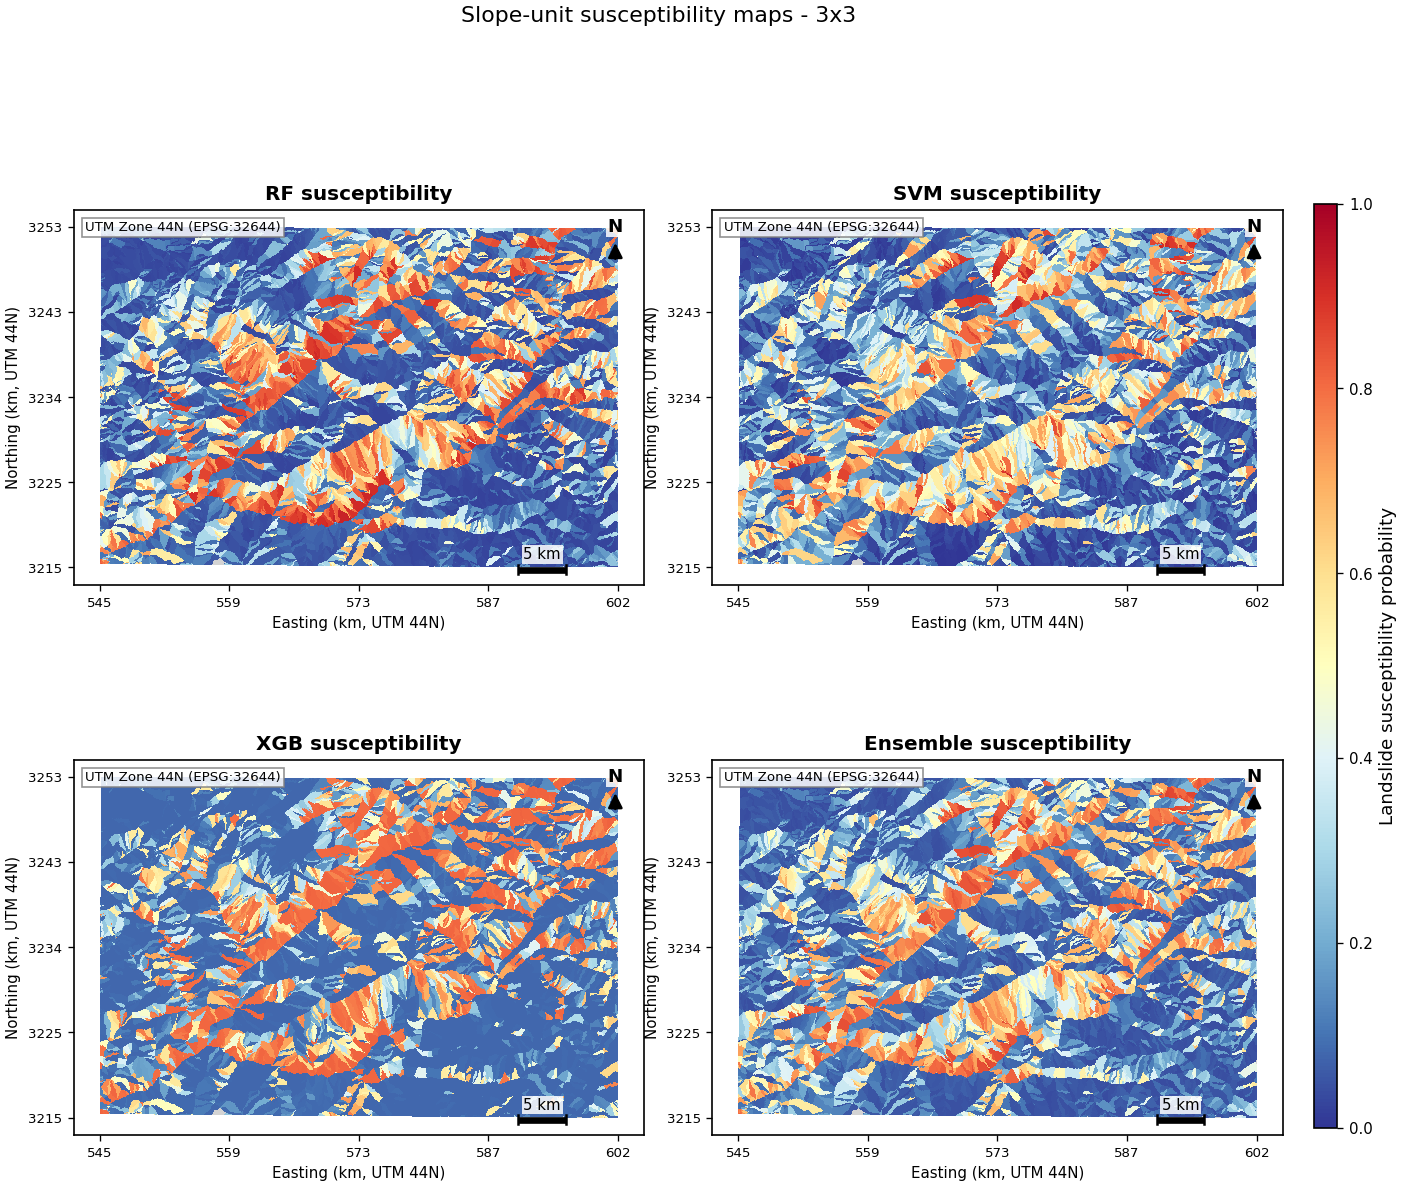

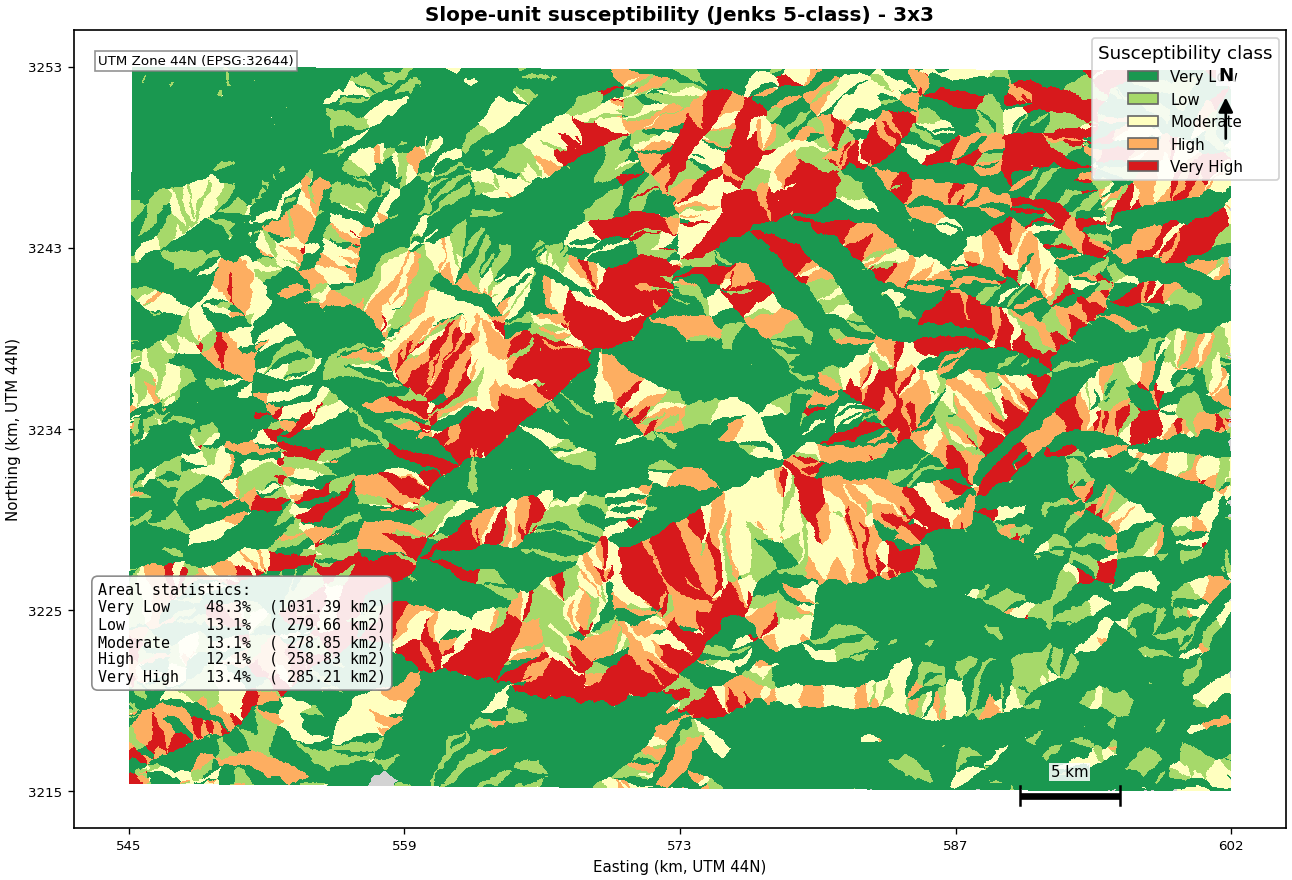

    class  lower  upper  units  area_km2  percent
 Very Low 0.0000 0.1494   3999   1031.39    48.33
      Low 0.1494 0.3125   1822    279.66    13.11
 Moderate 0.3125 0.5042   1228    278.85    13.07
     High 0.5042 0.6842   1395    258.83    12.13
Very High 0.6842 1.0000   1431    285.21    13.37


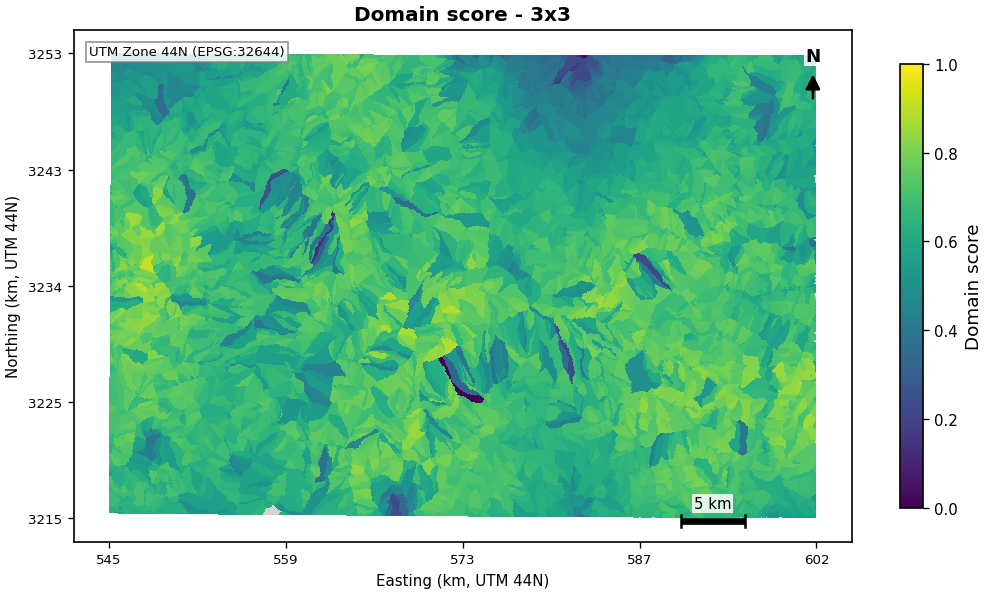

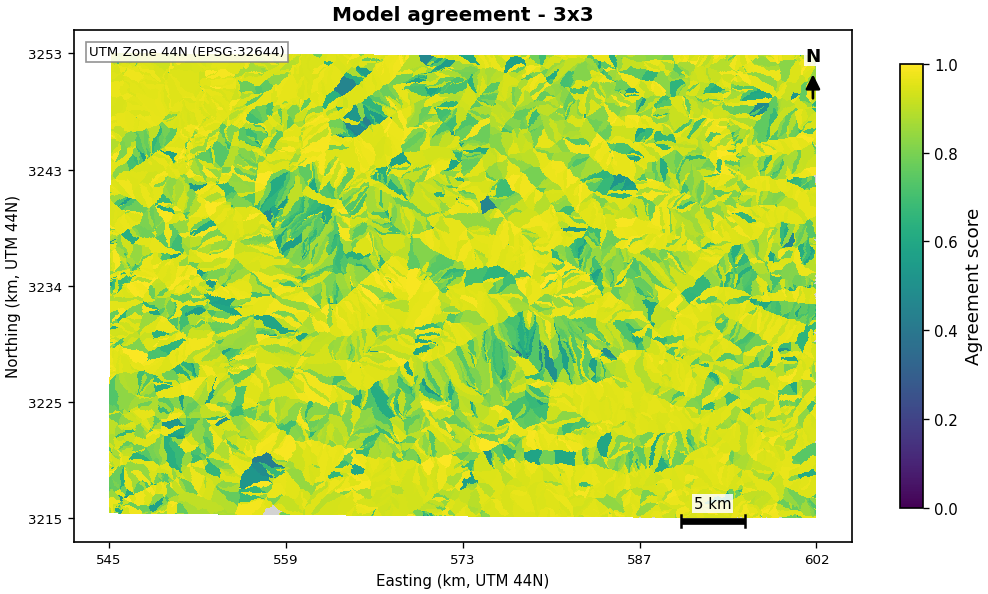

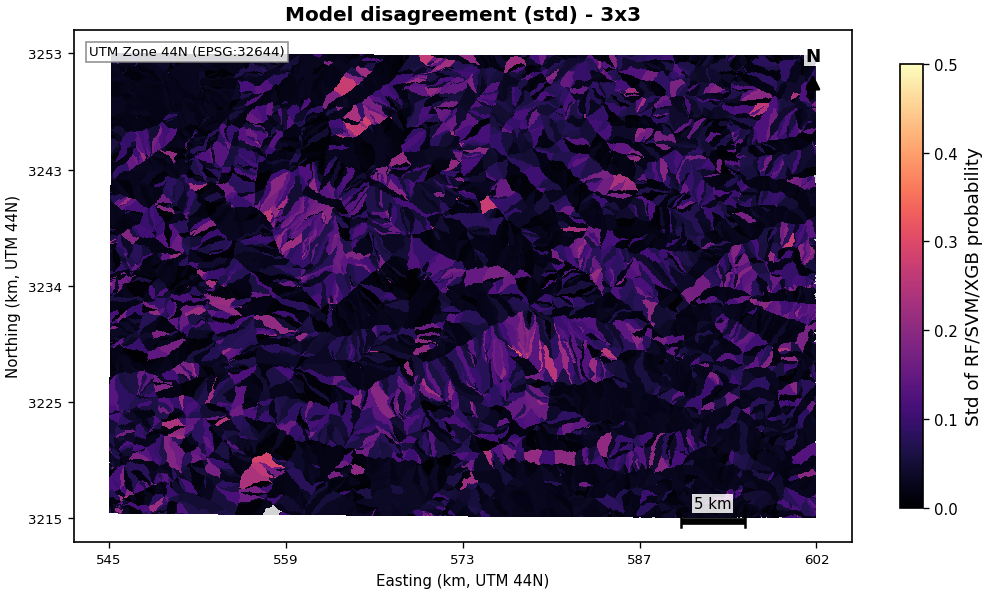

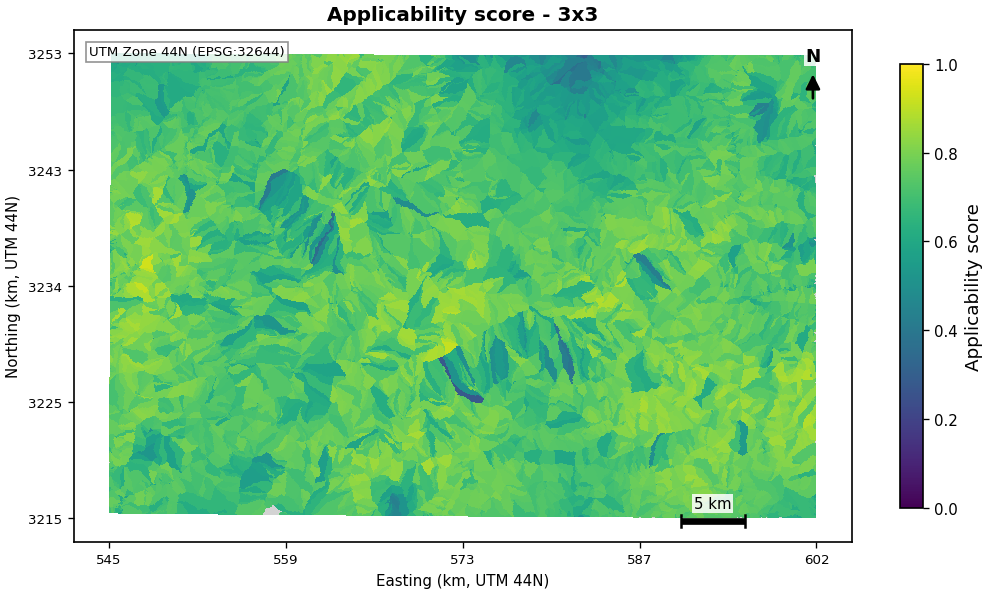

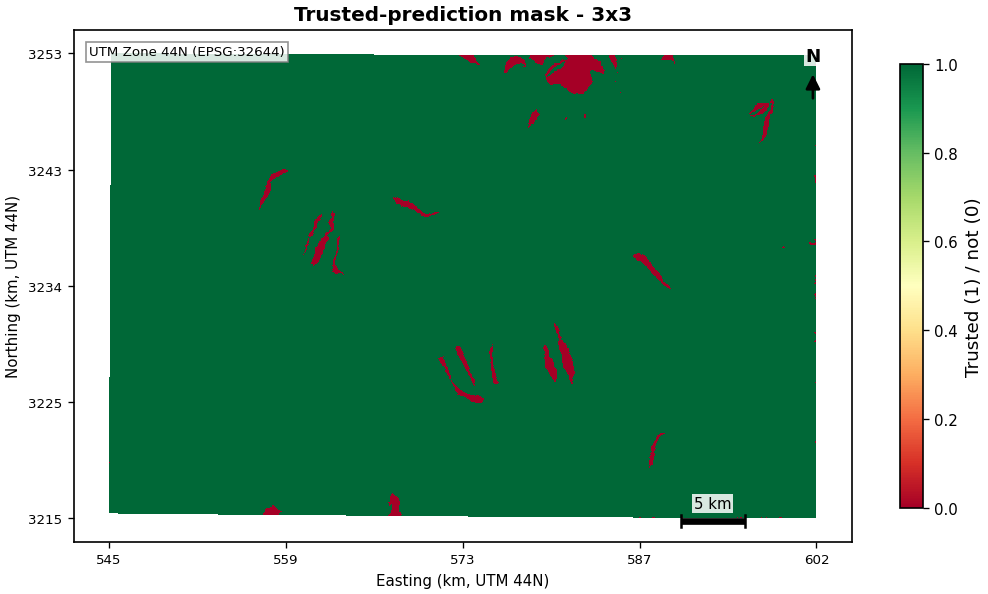

RasterioIOError: Attempt to create new tiff file '/content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/slope_unit_maps/3x3/maps/RF_susceptibility_3x3.tif' failed: /content/drive/MyDrive/RemoteSensingResearchRelated/ColabNotebooks/slope_unit_maps/3x3/maps/RF_susceptibility_3x3.tif: Operation not supported

In [ ]:
# =========================================================
# 4. MAIN LOOP
# =========================================================
all_summaries = []

for grid in grids:
    print(f"\n{'='*25} GRID: {grid} {'='*25}")
    grid_out = os.path.join(output_base_dir, grid)
    make_dir(grid_out); make_dir(os.path.join(grid_out, "maps")); make_dir(os.path.join(grid_out, "pngs"))

    gpkg_path = os.path.join(su_dir, f"su_{grid}.gpkg")
    csv_path  = os.path.join(su_dir, f"ls_slp_{grid}.csv")
    if not os.path.exists(gpkg_path):
        print(f"  [skip] missing slope-unit polygons: {gpkg_path}"); continue

    bundle, feats, models = load_models_for_grid(grid)
    print("  features used by models (%d):" % len(feats), feats)

    # ---- load ALL slope-unit polygons (features precomputed in the gpkg) -----
    gdf = gpd.read_file(gpkg_path)
    print("  slope-unit polygons:", len(gdf), "| CRS:", gdf.crs)
    missing = [f for f in feats if f not in gdf.columns]
    if missing:
        raise ValueError(f"gpkg is missing model feature columns: {missing}")

    X_all = gdf[feats].apply(pd.to_numeric, errors="coerce")
    valid = X_all.notna().all(axis=1).values
    Xv = X_all[valid]
    print("  valid units (no NaN in features):", int(valid.sum()), "/", len(gdf))

    # ---- predictions ---------------------------------------------------------
    ens, cols = ensemble_predict_proba(models, Xv)
    prob = {"RF": cols[0], "SVM": cols[1], "XGB": cols[2], "Ensemble": ens}

    # ---- applicability domain (fit on the labelled training sample) ----------
    train = pd.read_csv(csv_path)[feats].dropna()
    ad = fit_applicability_domain(train)
    domain, dist = compute_domain_score(Xv, ad)
    agree, std3  = compute_agreement_score(cols)
    applic = (0.7 * domain + 0.3 * agree).astype(np.float32)

    # ---- attach to geodataframe (NaN for invalid units) ----------------------
    def scatter(arr):
        out = np.full(len(gdf), np.nan, dtype="float32"); out[valid] = arr; return out
    for nm in ["RF", "SVM", "XGB", "Ensemble"]:
        gdf[f"{nm}_prob"] = scatter(prob[nm])
    gdf["Domain_score"]   = scatter(domain)
    gdf["Agreement_score"] = scatter(agree)
    gdf["Applicability"]  = scatter(applic)
    gdf["Mahalanobis"]    = scatter(dist)
    gdf["Model_disagreement_std"] = scatter(std3)   # raw per-unit std of the 3 model probs
    gdf["Trusted"]        = (gdf["Applicability"] >= 0.5).astype("float32")

    # ---- write GeoPackage ----------------------------------------------------
    gpkg_out = os.path.join(grid_out, "maps", f"Slope_susceptibility_{grid}.gpkg")
    gdf.to_file(gpkg_out, driver="GPKG")
    print("  wrote GeoPackage:", gpkg_out)

    # ---- PNG maps ------------------------------------------------------------
    pdir = os.path.join(grid_out, "pngs")
    for nm in ["RF", "SVM", "XGB", "Ensemble"]:
        plot_single_map(gdf, f"{nm}_prob", f"{nm} susceptibility - {grid}",
                        os.path.join(pdir, f"{nm}_susceptibility_{grid}.png"))
    plot_multi_model(gdf, grid, os.path.join(pdir, f"Multi_model_susceptibility_{grid}.png"))
    areal_df = plot_classified(gdf, grid, os.path.join(pdir, f"Classified_susceptibility_{grid}.png"))
    areal_df.to_csv(os.path.join(grid_out, f"{grid}_areal_statistics.csv"), index=False)
    print(areal_df.to_string(index=False))

    # applicability-domain layers
    plot_single_map(gdf, "Domain_score", f"Domain score - {grid}",
                    os.path.join(pdir, f"Domain_score_{grid}.png"),
                    cmap="viridis", cbar_label="Domain score")
    plot_single_map(gdf, "Agreement_score", f"Model agreement - {grid}",
                    os.path.join(pdir, f"Agreement_score_{grid}.png"),
                    cmap="viridis", cbar_label="Agreement score")
    plot_single_map(gdf, "Model_disagreement_std", f"Model disagreement (std) - {grid}",
                    os.path.join(pdir, f"Model_disagreement_std_{grid}.png"),
                    cmap="magma", vmin=0, vmax=0.5, cbar_label="Std of RF/SVM/XGB probability")
    plot_single_map(gdf, "Applicability", f"Applicability score - {grid}",
                    os.path.join(pdir, f"Applicability_score_{grid}.png"),
                    cmap="viridis", cbar_label="Applicability score")
    plot_single_map(gdf, "Trusted", f"Trusted-prediction mask - {grid}",
                    os.path.join(pdir, f"Trusted_mask_{grid}.png"),
                    cmap="RdYlGn", vmin=0, vmax=1, cbar_label="Trusted (1) / not (0)")

    # ---- GeoTIFF rasterisations ---------------------------------------------
    # Burn every per-unit layer to a GeoTIFF so the slope-unit maps/ folder mirrors
    # the pixel pipeline exactly (same file names, same EPSG:32644, 25 m grid).
    if EXPORT_GEOTIFF:
        mdir = os.path.join(grid_out, "maps")
        tif_layers = {
            "RF_susceptibility":       "RF_prob",
            "SVM_susceptibility":      "SVM_prob",
            "XGB_susceptibility":      "XGB_prob",
            "Ensemble_susceptibility": "Ensemble_prob",
            "Domain_score":            "Domain_score",
            "Agreement_score":         "Agreement_score",
            "Applicability_score":     "Applicability",
            "Trusted_mask":            "Trusted",
            "Model_disagreement_std":  "Model_disagreement_std",
            "Mahalanobis_distance":    "Mahalanobis",
        }
        for fname, col in tif_layers.items():
            rasterize_column(gdf, col, os.path.join(mdir, f"{fname}_{grid}.tif"))
        print(f"  wrote {len(tif_layers)} GeoTIFF layers to {mdir}")

    # ---- summary -------------------------------------------------------------
    summary = {
        "grid": grid,
        "features": feats,
        "n_slope_units_total": int(len(gdf)),
        "n_slope_units_valid": int(valid.sum()),
        "training_units": int(len(train)),
        "domain_threshold_95pct_train_mahalanobis": ad["threshold"],
        "applicability_formula": "0.7 * domain_score + 0.3 * agreement_score",
        "applicability_threshold_binary_mask": 0.5,
        "ensemble_method": "equal-weight mean probability",
        "geotiff_layers": list(tif_layers.keys()) if EXPORT_GEOTIFF else [],
        "outputs_in": grid_out,
    }
    with open(os.path.join(grid_out, f"{grid}_prediction_summary.json"), "w") as f:
        json.dump(summary, f, indent=4)
    all_summaries.append(summary)
    print(f"  finished grid: {grid}")
    gc.collect()

print("\nAll slope-unit susceptibility, ensemble, and applicability maps created.")
for s in all_summaries:
    print(f"  {s['grid']}: {s['n_slope_units_valid']}/{s['n_slope_units_total']} units mapped, "
          f"d95={s['domain_threshold_95pct_train_mahalanobis']:.3f}")
